#  <center> Pandas - Additional Material

In [1]:
# Required imports
import numpy as np
import pandas as pd

# A seeded random number generator, as in Lecture 2
rng = np.random.default_rng(0)

# Reading HTML and SQL

### HTML

Pandas' `read_html()` function reads the tables on a web page and returns a list of DataFrames, one for each table. It needs an HTML parser, `lxml`, which isn't in the `mpm2026` environment: without it, pandas raises an `ImportError` that asks you to install it. To try the example below, install it from your Ubuntu (WSL) terminal, with `mpm2026` activated,

```bash
pip install lxml
```

and restart the notebook's kernel. (`read_html()` also needs to download the page, so you need to be online.)

For example, the US Federal Deposit Insurance Corporation (FDIC) publishes a table of failed banks:

```python
df = pd.read_html('https://www.fdic.gov/bank-failures/failed-bank-list')[0]
print(df.head())  # Shows the first 5 rows of the DataFrame
```

On 7 October 2026, this gave a DataFrame of the 25 most recent bank failures, with the columns `Bank Name`, `City`, `State`, `Cert`, `Acquiring Institution`, `Closing Date` and `Fund  Sort ascending`. The last name includes the text of a sort button in the page's table header: tables from the web often need some tidying (`rename()`, in the lecture).

### SQL in Pandas

The `pandas.io.sql` module provides a set of query wrappers to facilitate data retrieval and reduce dependency on database-specific APIs. Database abstraction is supported through SQLAlchemy, if installed. Additionally, you will need a driver library specific to your database. Examples include `psycopg2` for PostgreSQL or `pymysql` for MySQL. For SQLite, the driver is included in Python’s standard library by default. You can find an overview of supported drivers for each SQL dialect in the [SQLAlchemy documentation](https://docs.sqlalchemy.org).

If SQLAlchemy is not installed (it isn't in `mpm2026`), pandas can still use an **SQLite** database, through a connection from the standard library's `sqlite3` module: that is what the example below does. Other databases need SQLAlchemy (or an ADBC driver).

Refer to the pandas cookbook for advanced SQL strategies.

#### Key Functions:
- **`read_sql_table(table_name, con[, schema, ...])`**  
  Read a SQL database table into a DataFrame (needs SQLAlchemy).

- **`read_sql_query(sql, con[, index_col, ...])`**  
  Read a SQL query into a DataFrame.

- **`read_sql(sql, con[, index_col, ...])`**  
  Read a SQL query or database table into a DataFrame (a table name, rather than a query, needs SQLAlchemy).

- **`DataFrame.to_sql(name, con[, schema, if_exists, ...])`**  
  Write records from a DataFrame to a SQL database.

In [2]:
import sqlite3

con = sqlite3.connect(':memory:')   # a temporary SQLite database, held in memory
df = pd.DataFrame({'Course': ['NPP', 'NPP', 'EDMS', 'EDMS', 'CM', 'CM'],
                   'Person': ['Bob', 'Sam', 'Amy', 'Vanessa', 'Carl', 'Sarah'],
                   'Marks': [70, 75, 80, 65, 60, 90]})
df.to_sql('marks', con, index=False)   # write df to a table called 'marks'
sql_df = pd.read_sql('SELECT Course, AVG(Marks) AS mean_mark FROM marks GROUP BY Course', con)
con.close()
sql_df

,Course,mean_mark
0,CM,75.0
1,EDMS,72.5
2,NPP,72.5


With SQLAlchemy installed (`pip install sqlalchemy`), `con` can instead be an *engine*, such as `create_engine('sqlite:///:memory:')` from `sqlalchemy`, and then `pd.read_sql('marks', engine)` reads a whole table by its name.

# Multi-Index and Index Hierarchy

Let us go over how to work with Multi-Index, first we'll create a quick example of what a Multi-Indexed DataFrame would look like:

In [3]:
# Index Levels
outside = ['G1','G1','G1','G2','G2','G2']
inside = [1,2,3,1,2,3]
hier_index = list(zip(outside,inside))
hier_index = pd.MultiIndex.from_tuples(hier_index)

In [4]:
hier_index

MultiIndex([('G1', 1),
            ('G1', 2),
            ('G1', 3),
            ('G2', 1),
            ('G2', 2),
            ('G2', 3)],
           )

In [5]:
df = pd.DataFrame(rng.standard_normal((6, 2)),index=hier_index,columns=['A','B'])
df

A         B
G1 1  0.125730 -0.132105
   2  0.640423  0.104900
   3 -0.535669  0.361595
G2 1  1.304000  0.947081
   2 -0.703735 -1.265421
   3 -0.623274  0.041326

Now let's show how to index this! For index hierarchy we use df.loc[], if this was on the columns axis, you would just use normal bracket notation df[]. Calling one level of the index returns the sub-dataframe:

In [6]:
df.loc['G1']

,A,B
1,0.125730,-0.132105
2,0.640423,0.104900
3,-0.535669,0.361595


In [7]:
df.loc['G1'].loc[1]

A    0.125730
B   -0.132105
Name: 1, dtype: float64

In [8]:
df.index.names

FrozenList([None, None])

In [9]:
df.index.names = ['Group','Num']

In [10]:
df

A         B
Group Num                    
G1    1    0.125730 -0.132105
      2    0.640423  0.104900
      3   -0.535669  0.361595
G2    1    1.304000  0.947081
      2   -0.703735 -1.265421
      3   -0.623274  0.041326

In [11]:
df.xs('G1')  # xs is used to return a cross-section from a DataFrame with a MultiIndex

,A,B
Num,,
1,0.125730,-0.132105
2,0.640423,0.104900
3,-0.535669,0.361595


## Pandas Built-in Data Visualisation

Pandas built-in capabilities for data visualisation! It's built off of matplotlib, but it's baked into pandas for easier usage!

For more information on the following topics visit https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html<br>
For a nice graphic showing the anatomy of a figure with terminology, visit https://matplotlib.org/stable/users/explain/quick_start.html#parts-of-a-figure



In [12]:
import matplotlib.pyplot as plt
%matplotlib inline

# Plot Types

There are several plot types built into pandas; most of them are statistical by nature:

<pre>
df.plot.hist()     histogram
df.plot.bar()      bar chart
df.plot.barh()     horizontal bar chart
df.plot.line()     line chart
df.plot.area()     area chart
df.plot.scatter()  scatter plot
df.plot.box()      box plot
df.plot.kde()      kde plot
df.plot.hexbin()   hexagonal bin plot
df.plot.pie()      pie chart</pre>

You can also call specific plots by passing their name as an argument, as with `df.plot(kind='area')`.


In [13]:
df1 = pd.read_csv('inputs/df1.csv', index_col=0)
df2 = pd.read_csv('inputs/df2.csv')

## Histograms
This is one of the most commonly used plots. Histograms describe the distribution of continuous data by dividing the data into "bins" of equal width, and plotting the number of values that fall into each bin. <a href='https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.hist.html'>[reference]</a>

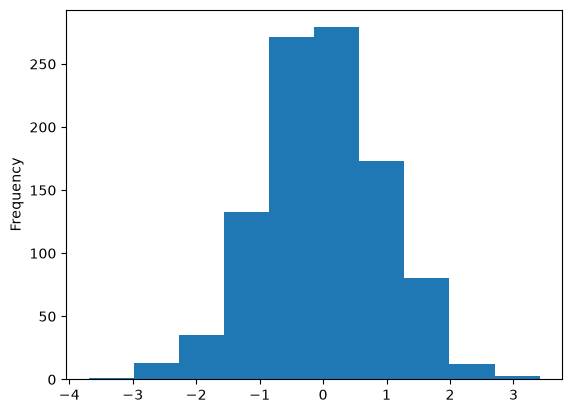

In [14]:
df1['A'].plot.hist()
plt.show()

We can add settings to do things like bring the x- and y-axis values to the edge of the graph, and insert lines between vertical bins:

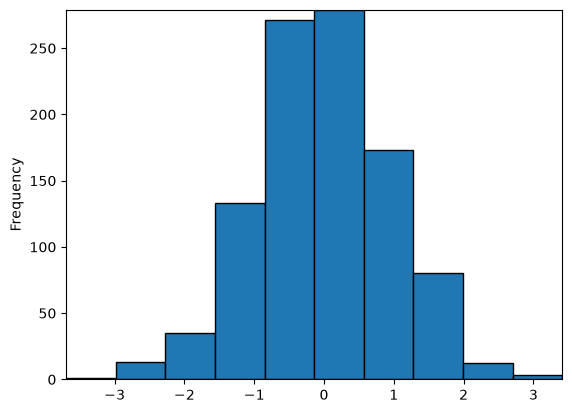

In [15]:
df1['A'].plot.hist(edgecolor='k').autoscale(enable=True, axis='both', tight=True)
plt.show()

You can use any [matplotlib color spec](https://matplotlib.org/api/colors_api.html) for **edgecolor**, such as `'b', 'g', 'r', 'c', 'm', 'y', 'k', 'w'`, or the string representation of a float value for shades of grey, such as `'0.5'`

For **autoscale** the axis can be set to `'x'`, `'y'` or `'both'`

We can also change the number of bins (the range of values over which frequencies are calculated) from the default value of 10:

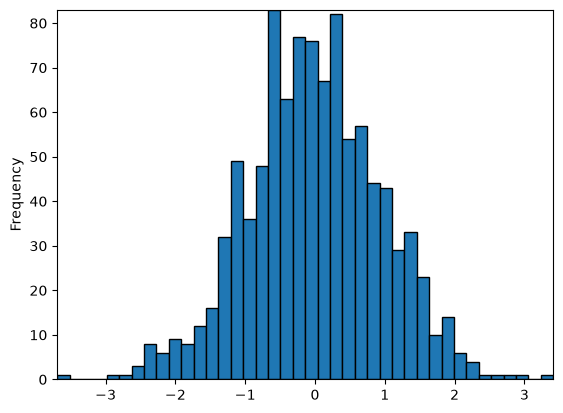

In [16]:
df1['A'].plot.hist(bins=40, edgecolor='k').autoscale(enable=True, axis='both', tight=True)
plt.show()

## Barplots
Barplots are similar to histograms, except that they deal with discrete data, and often reflect multiple variables. <a href='https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html'>[reference]</a>

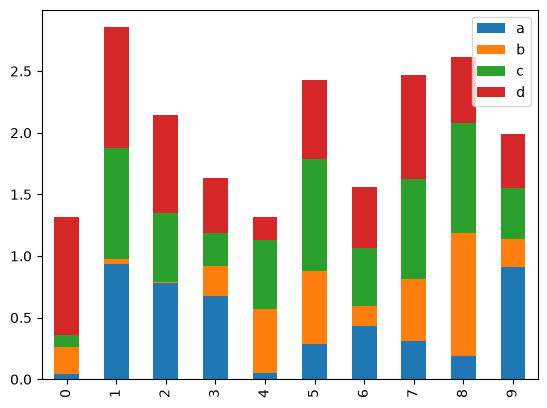

In [17]:
df2.plot.bar(stacked=True)
plt.show()

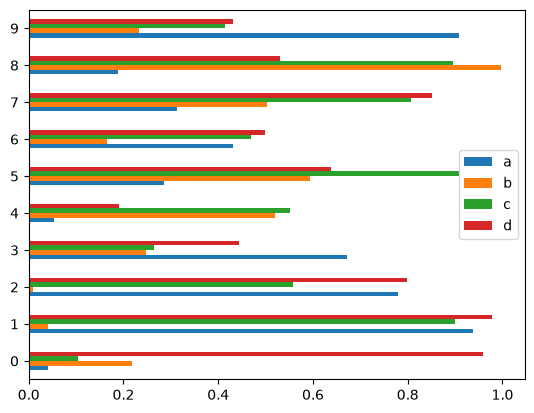

In [18]:
# USE .barh() TO DISPLAY A HORIZONTAL BAR PLOT
df2.plot.barh()
plt.show()

## Line Plots
Line plots are used to compare two or more variables. By default the x-axis values are taken from the index. <a href='https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.line.html'>[reference]</a>

Line plots happen to be the default pandas plot. They are accessible through <tt>df.plot()</tt> as well as <tt>df.plot.line()</tt>

<table style="display: inline-block">
    <tr><th>PROPERTY</th><th>CODE</th><th>VALUE</th><th>EFFECT</th></tr>
    <tr><td>linestyle</td><td><tt>ls</tt></td><td><tt>'-'</tt></td><td>solid line (default)</td></tr>
    <tr><td>linestyle</td><td><tt>ls</tt></td><td><tt>'--'</tt></td><td>dashed line</td></tr>
    <tr><td>linestyle</td><td><tt>ls</tt></td><td><tt>'-.'</tt></td><td>dashed/dotted line</td></tr>
    <tr><td>linestyle</td><td><tt>ls</tt></td><td><tt>':'</tt></td><td>dotted line</td></tr>
    <tr><td>color</td><td><tt>c</tt></td><td>string</td><td></td></tr>
    <tr><td>linewidth</td><td><tt>lw</tt></td><td>float</td><td></td></tr>
</table>

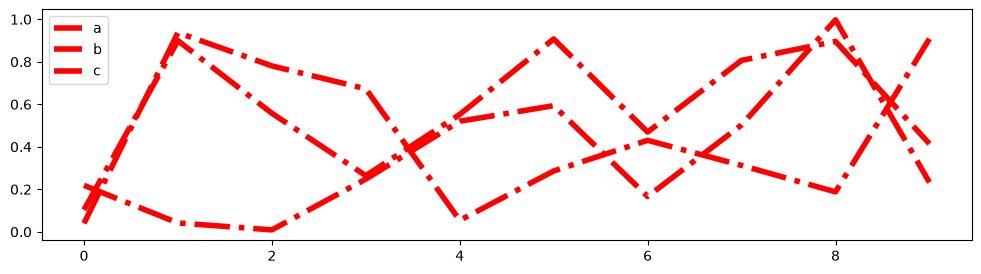

In [19]:
df2.plot.line(y=['a', 'b', 'c'], figsize=(12, 3), ls='-.', c='r', lw=4)
plt.show()

### Object-oriented plotting

When we call <tt>df.plot()</tt>, pandas returns a <tt>matplotlib.axes.Axes</tt> object. We can set labels
on that object so long as we do it in the same jupyter cell. Setting an autoscale is done the same way.

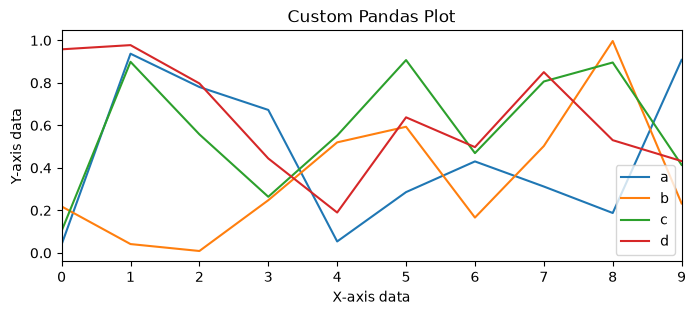

In [20]:
title='Custom Pandas Plot'
ylabel='Y-axis data'
xlabel='X-axis data'

ax = df2.plot(figsize=(8, 3), title=title)
ax.set(xlabel=xlabel, ylabel=ylabel)
ax.autoscale(axis='x', tight=True);

## Plot Legend Placement
Pandas tries to optimise placement of the legend to reduce overlap on the plot itself. However, we can control the placement ourselves, and even place the legend outside of the plot. We do this through the <tt>.legend()</tt> method. <a href='https://matplotlib.org/api/_as_gen/matplotlib.pyplot.legend.html'>[reference]</a>

For starters we can pass a location code. <tt>.legend(loc=1)</tt> places the legend in the upper-right corner of the plot.<br>Alternatively we can pass a location string: <tt>.legend(loc='upper right')</tt> does the same thing.

<table style="display: inline-block">
<tr><th>LOCATION CODE</th><th>LOCATION STRING</th></tr>
<tr><td>0</td><td>'best'</td></tr>
<tr><td>1</td><td>'upper right'</td></tr>
<tr><td>2</td><td>'upper left'</td></tr>
<tr><td>3</td><td>'lower left'</td></tr>
<tr><td>4</td><td>'lower right'</td></tr>
<tr><td>5</td><td>'right'</td></tr>
<tr><td>6</td><td>'center left'</td></tr>
<tr><td>7</td><td>'center right'</td></tr>
<tr><td>8</td><td>'lower center'</td></tr>
<tr><td>9</td><td>'upper center'</td></tr>
<tr><td>10</td><td>'center'</td></tr>
</table>

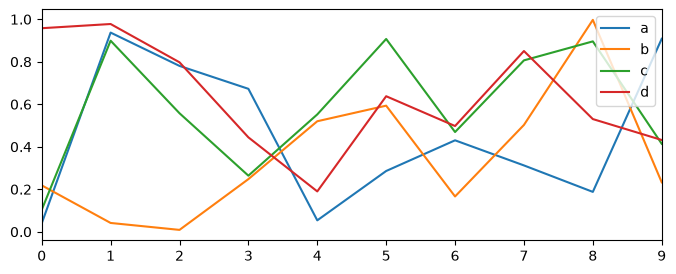

In [21]:
ax = df2.plot(figsize=(8, 3))
ax.autoscale(axis='x', tight=True)
ax.legend(loc=1)
plt.show()

We can pass a second argument, <tt>bbox_to_anchor</tt> that treats the value passed in through <tt>loc</tt> as an anchor point, and positions the legend along the x and y axes based on a two-value tuple.

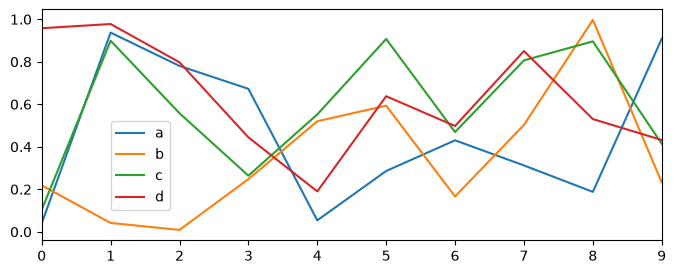

In [22]:
ax = df2.plot(figsize=(8, 3))
ax.autoscale(axis='x', tight=True)
ax.legend(loc=3, bbox_to_anchor=(0.1, 0.1))
plt.show()

### Placing the Legend Outside the Plot
In the above plot we passed <tt>(0.1,0.1)</tt> as our two-item tuple. This places the legend slightly to the right and slightly upward.<br>To place the legend outside the plot on the right-hand side, pass a value greater than or equal to 1 as the first item in the tuple.

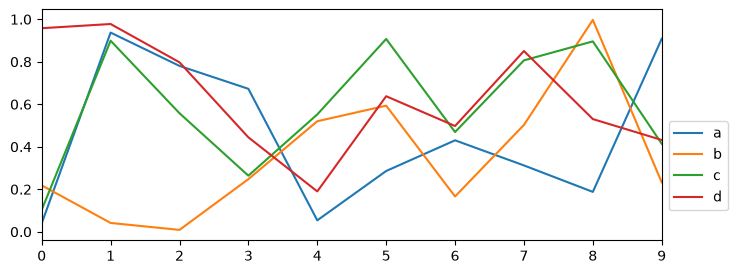

In [23]:
ax = df2.plot(figsize=(8, 3))
ax.autoscale(axis='x', tight=True)
ax.legend(loc=3, bbox_to_anchor=(1.0, 0.1))
plt.show()

## Area Plots
Area plots represent cumulatively stacked line plots where the space between lines is emphasised with colours. <a href='https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.area.html'>[reference]</a>

- To produce a blended area plot, pass a <strong>stacked=False</strong> argument
- It often helps to mute the colours by passing an <strong>alpha</strong> transparency value between 0 and 1.

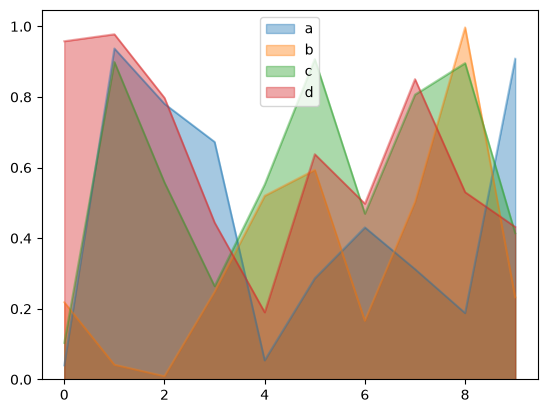

In [24]:
df2.plot.area(stacked=False, alpha=0.4)
plt.show()

## Scatter Plots
Scatter plots are a useful tool to quickly compare two variables, and to look for possible trends. <a href='https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html'>[reference]</a>

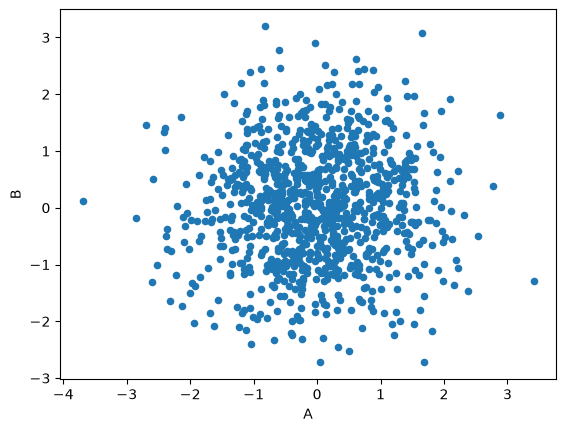

In [25]:
df1.plot.scatter(x='A', y='B')
plt.show()

### Scatter plots with colormaps
You can use <strong>c</strong> to colour each marker based off another column value. Use `cmap` to indicate which colormap to use.<br>
For all the available colormaps, check out: https://matplotlib.org/stable/users/explain/colors/colormaps.html

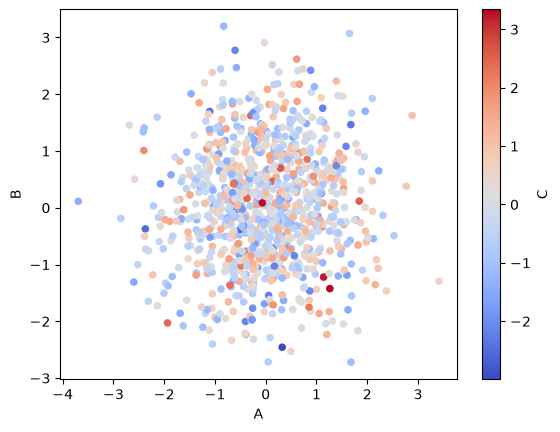

In [26]:
df1.plot.scatter(x='A', y='B', c='C', cmap='coolwarm')
plt.show()

### Scatter plots with sized markers
Alternatively you can use <strong>s</strong> to indicate marker size based off another column. <strong>s</strong> can be the name of a column, or an array of sizes: here we scale the values up, so that the markers are big enough to see. Sizes can't be negative, though, and some `df1['C']` values are (Matplotlib warns `invalid value encountered in sqrt`), so we clip them at 0 first:

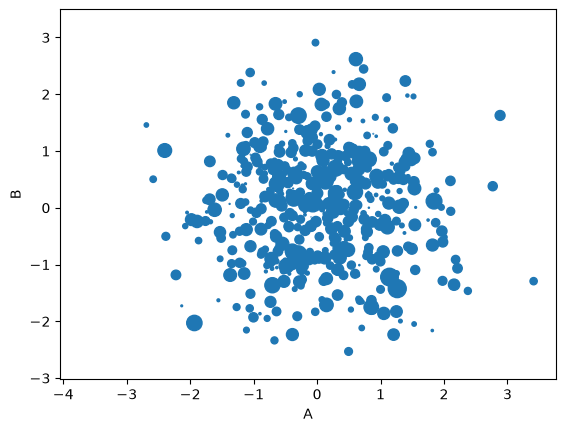

In [27]:
# Replace negative values or NaNs with 0 (in a new Series, so df1 itself is unchanged)
sizes = df1['C'].clip(lower=0).fillna(0)
df1.plot.scatter(x='A', y='B', s=sizes*50)
plt.show()

Clipping gives every negative value the same size, zero, though. Another way is to shift all the values up: the minimum value of `df1['C']` is about -3, so we can write a function that adds 3 to each value, and apply our function to the data with <strong>.apply(func)</strong>.

Also, these data points have a lot of overlap. We can address this issue by passing in an <strong>alpha</strong> blending value between 0 and 1 to make markers more transparent.

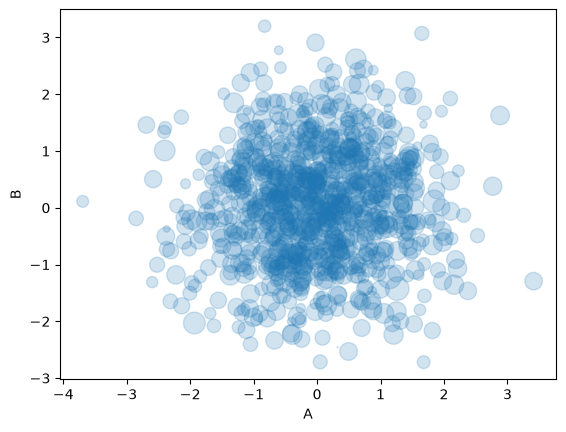

In [28]:
def add_three(val):
    return val+3

df1.plot.scatter(x='A', y='B', s=df1['C'].apply(add_three)*45, alpha=0.2)
plt.show()

## BoxPlots
Box plots, aka "box and whisker diagrams", describe the distribution of data by dividing data into <em>quartiles</em> about the median.<br>
Look <a href='https://en.wikipedia.org/wiki/Box_plot'>here</a> for a description of boxplots. <a href='https://pandas.pydata.org/docs/user_guide/visualization.html#box-plots'>[reference]</a>

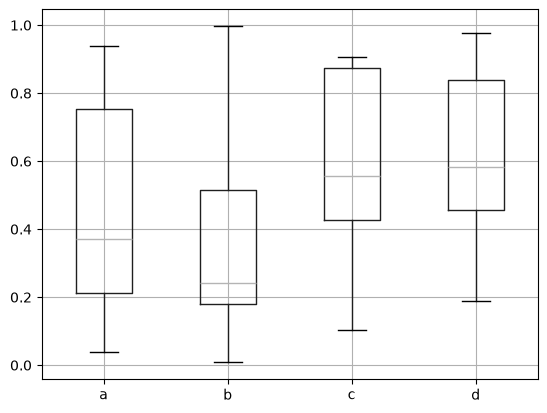

In [29]:
df2.boxplot()
plt.show()

### Boxplots with Groupby
To draw boxplots based on groups, first pass in a list of columns you want plotted (including the groupby column), then pass <strong>by='column_name'</strong> into <tt>.boxplot()</tt>. Here we'll group records by the <strong>'e'</strong> column, and draw boxplots for the <strong>'b'</strong> column.

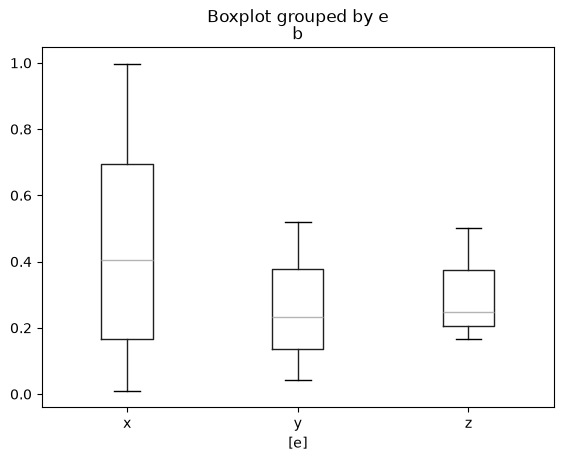

In [30]:
df2[['b','e']].boxplot(by='e', grid=False)
plt.show()

## Kernel Density Estimation (KDE) Plot
These plots are accessible either through <tt>df.plot.kde()</tt> or <tt>df.plot.density()</tt> <a href='https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.kde.html'>[reference]</a>

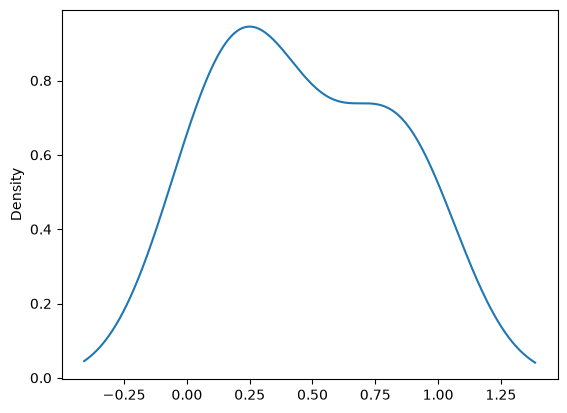

In [31]:
df2['a'].plot.kde()
plt.show()

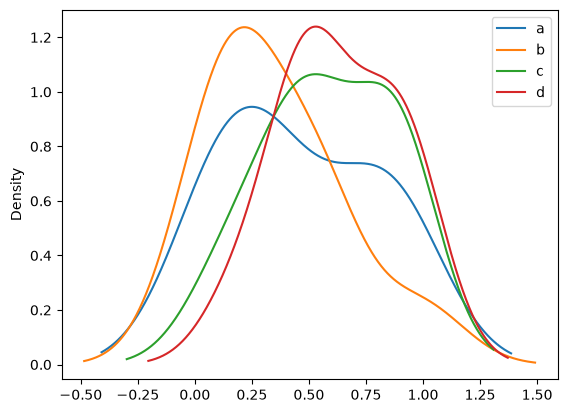

In [32]:
df2.plot.density()
plt.show()

## Hexagonal Bin Plot

Useful for Bivariate Data, alternative to scatterplot. <a href='https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.hexbin.html'>[reference]</a>

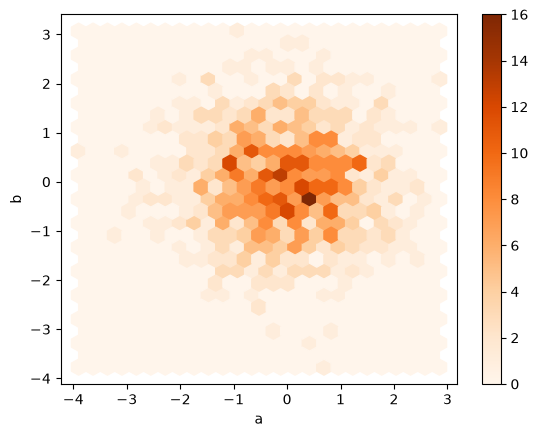

In [33]:
# FIRST CREATE A DATAFRAME OF RANDOM VALUES
df = pd.DataFrame(rng.standard_normal((1000, 2)), columns=['a', 'b'])

# MAKE A HEXAGONAL BIN PLOT
df.plot.hexbin(x='a',y='b',gridsize=25,cmap='Oranges')
plt.show()

## Timeseries with Pandas
### Pandas Datetime Index
For more on the pandas DatetimeIndex visit https://pandas.pydata.org/docs/user_guide/timeseries.html

In [34]:
# SEVEN HOURS FROM MIDNIGHT ON JULY 8TH, 2018 ('7/8/2018' IS READ MONTH FIRST)
idx = pd.date_range('7/8/2018', periods=7, freq='h')
idx

DatetimeIndex(['2018-07-08 00:00:00', '2018-07-08 01:00:00',
               '2018-07-08 02:00:00', '2018-07-08 03:00:00',
               '2018-07-08 04:00:00', '2018-07-08 05:00:00',
               '2018-07-08 06:00:00'],
              dtype='datetime64[us]', freq='h')

Another way is to convert incoming text with the <tt><strong>pd.to_datetime()</strong></tt> method:

In [35]:
idx = pd.to_datetime(["Jan 02, 2018", "24th May 2017 06:00 +4", "09/08/2018"],
                     format='mixed', errors='coerce', utc=True)
idx

DatetimeIndex(['2018-01-02 00:00:00+00:00', '2017-05-24 02:00:00+00:00',
               '2018-09-08 00:00:00+00:00'],
              dtype='datetime64[us, UTC]', freq=None)

Make sure to be consistent with DD/MM/YY(YY) or MM/DD/YY(YY) if giving numerical dates to avoid ambiguity.

Using a unix epoch time

In [36]:
pd.to_datetime(1490195805, unit='s')

Timestamp('2017-03-22 15:16:45')

Using a non-unix epoch origin

In [37]:
pd.to_datetime([1, 2, 3], unit='D',
               origin=pd.Timestamp('2022-08-01'))


DatetimeIndex(['2022-08-02', '2022-08-03', '2022-08-04'], dtype='datetime64[s]', freq=None)

A third way is to pass a list or an array of datetime objects into the <tt><strong>pd.DatetimeIndex()</strong></tt> method:

In [38]:
# Create a NumPy datetime array
some_dates = np.array(['2016-03-15', '2017-05-24', '2018-08-09'], dtype='datetime64[D]')
# Convert to an index
idx = pd.DatetimeIndex(some_dates)
idx

DatetimeIndex(['2016-03-15', '2017-05-24', '2018-08-09'], dtype='datetime64[s]', freq=None)

In [39]:
data = rng.standard_normal((3, 2))
cols = ['A','B']
df = pd.DataFrame(data,idx,cols)
df

,A,B
2016-03-15,-0.343553,-0.173336
2017-05-24,-1.473657,1.339149
2018-08-09,0.847816,-0.531995


In [40]:
df.index.max()

Timestamp('2018-08-09 00:00:00')

In [41]:
df.index.min()

Timestamp('2016-03-15 00:00:00')

### `pd.DateOffset()` and `pd.Timedelta()` function

Let’s see how we can use the Pandas `pd.Timedelta()` function to add a constant number of days to a column:


In [42]:
df['14 days later'] = df.index + pd.Timedelta(days=14)
df

,A,B,14 days later
2016-03-15,-0.343553,-0.173336,2016-03-29
2017-05-24,-1.473657,1.339149,2017-06-07
2018-08-09,0.847816,-0.531995,2018-08-23


In [43]:
df['14 days earlier'] = df.index - pd.DateOffset(days=14)
df

,A,B,14 days later,14 days earlier
2016-03-15,-0.343553,-0.173336,2016-03-29,2016-03-01
2017-05-24,-1.473657,1.339149,2017-06-07,2017-05-10
2018-08-09,0.847816,-0.531995,2018-08-23,2018-07-26


**Exercise:** for people `A`, `B` and `C`, create a DataFrame with a hypothetical arrival date and length of stay for each, then calculate their departure dates. Then do it the other way round: from departure dates and lengths of stay, calculate the arrival dates.

In [44]:
# Solutions are in the exercises-solutions notebook

## Time Resampling
When calling `.resample()` you first need to pass in a **rule** parameter, then you need to call some sort of aggregation function.

The **rule** parameter describes the frequency with which to apply the aggregation function (daily, monthly, yearly, etc.)<br>
It is passed in using an "offset alias" - refer to the table below. [[reference](https://pandas.pydata.org/docs/user_guide/timeseries.html#offset-aliases)]

The aggregation function is needed because, due to resampling, we need some sort of mathematical rule to join the rows (mean, sum, count, etc.)

Let's read some tide gauge data (Source: [NOAA](https://tidesandcurrents.noaa.gov/map/)):

In [45]:
df = pd.read_csv('inputs/Tide.csv', index_col='Date', parse_dates=True, dayfirst=True)

<Axes: xlabel='Date'>

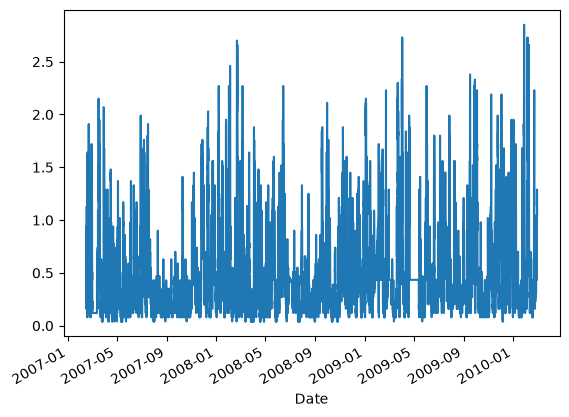

In [46]:
df['Hs'].plot()

In [47]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 26648 entries, 2007-02-14 16:30:00 to 2010-02-28 23:30:00
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hs      26648 non-null  float64
 1   Hs_hat  26648 non-null  float64
dtypes: float64(2)
memory usage: 624.6 KB


In [48]:
df.index

DatetimeIndex(['2007-02-14 16:30:00', '2007-02-14 17:30:00',
               '2007-02-14 18:30:00', '2007-02-14 19:30:00',
               '2007-02-14 20:30:00', '2007-02-14 21:30:00',
               '2007-02-14 22:30:00', '2007-02-14 23:30:00',
               '2007-02-15 00:30:00', '2007-02-15 01:30:00',
               ...
               '2010-02-28 14:30:00', '2010-02-28 15:30:00',
               '2010-02-28 16:30:00', '2010-02-28 17:30:00',
               '2010-02-28 18:30:00', '2010-02-28 19:30:00',
               '2010-02-28 20:30:00', '2010-02-28 21:30:00',
               '2010-02-28 22:30:00', '2010-02-28 23:30:00'],
              dtype='datetime64[us]', name='Date', length=26648, freq=None)

<table style="display: inline-block">
    <caption style="text-align: center"><strong>TIME SERIES OFFSET ALIASES</strong></caption>
<tr><th>ALIAS</th><th>DESCRIPTION</th></tr>
<tr><td>B</td><td>business day frequency</td></tr>
<tr><td>C</td><td>custom business day frequency</td></tr>
<tr><td>D</td><td>calendar day frequency</td></tr>
<tr><td>W</td><td>weekly frequency</td></tr>
<tr><td>ME</td><td>month end frequency</td></tr>
<tr><td>SME</td><td>semi-month end frequency (15th and end of month)</td></tr>
<tr><td>BME</td><td>business month end frequency</td></tr>
<tr><td>CBME</td><td>custom business month end frequency</td></tr>
<tr><td>MS</td><td>month start frequency</td></tr>
<tr><td>SMS</td><td>semi-month start frequency (1st and 15th)</td></tr>
<tr><td>BMS</td><td>business month start frequency</td></tr>
<tr><td>CBMS</td><td>custom business month start frequency</td></tr>
<tr><td>QE</td><td>quarter end frequency</td></tr>
<tr><td>BQE</td><td>business quarter end frequency</td></tr></table>

<table style="display: inline-block; margin-left: 40px">
<caption style="text-align: center"></caption>
<tr><th>ALIAS</th><th>DESCRIPTION</th></tr>
<tr><td>QS</td><td>quarter start frequency</td></tr>
<tr><td>BQS</td><td>business quarter start frequency</td></tr>
<tr><td>YE</td><td>year end frequency</td></tr>
<tr><td>BYE</td><td>business year end frequency</td></tr>
<tr><td>YS</td><td>year start frequency</td></tr>
<tr><td>BYS</td><td>business year start frequency</td></tr>
<tr><td>h</td><td>hourly frequency</td></tr>
<tr><td>bh</td><td>business hour frequency</td></tr>
<tr><td>min</td><td>minutely frequency</td></tr>
<tr><td>s</td><td>secondly frequency</td></tr>
<tr><td>ms</td><td>milliseconds</td></tr>
<tr><td>us</td><td>microseconds</td></tr>
<tr><td>ns</td><td>nanoseconds</td></tr></table>

In [49]:
# hourly >> yearly (we can use mean, max, ... or use our own function)
def first_day(entry):
    if len(entry):
        return entry.iloc[0]  # Use iloc for positional access

# 'YE' for year-end frequency
df.resample(rule='YE').apply(first_day)  # You can still use .mean if needed

,Hs,Hs_hat
Date,,
2007-12-31,0.94,0.282
2008-12-31,0.35,0.105
2009-12-31,0.20,0.060
2010-12-31,0.27,0.081


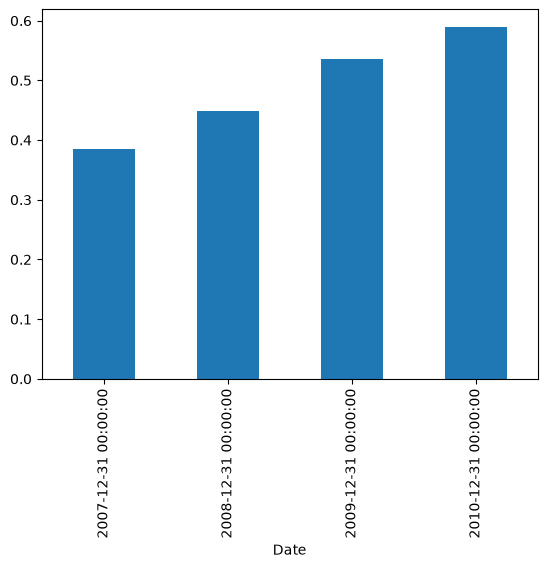

In [50]:
df['Hs'].resample(rule='YE').mean().plot.bar()
plt.show()

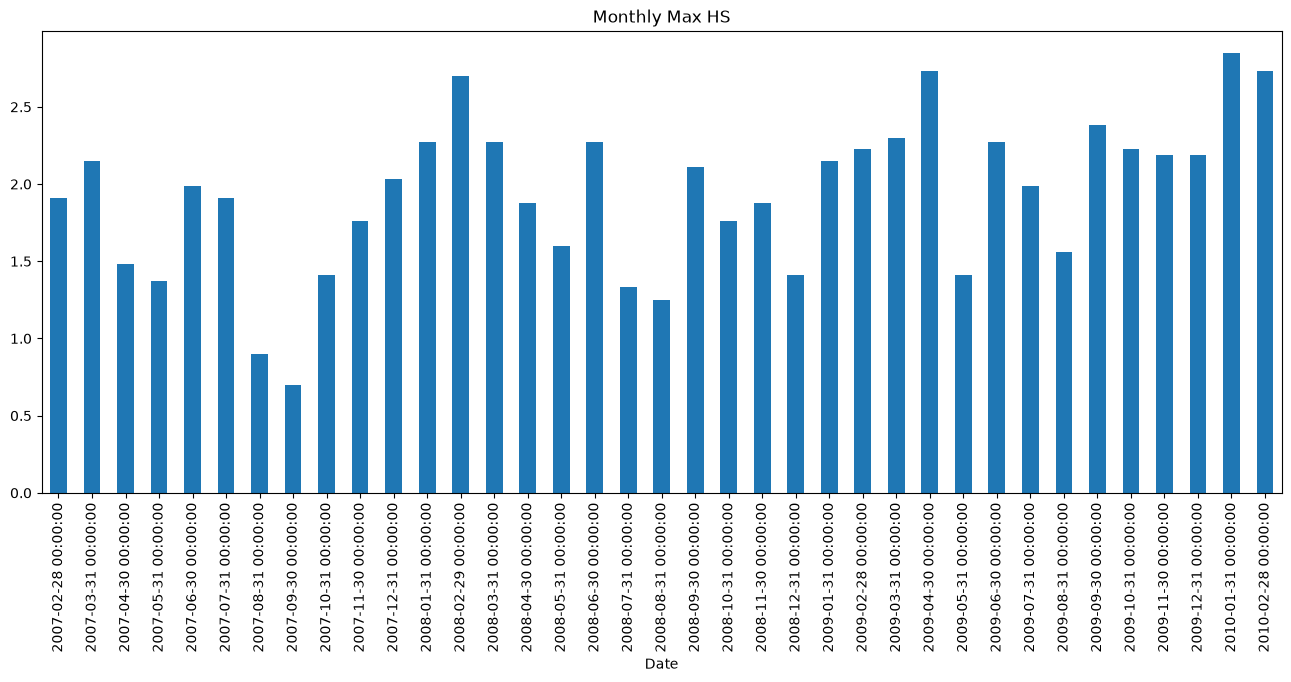

In [51]:
title = 'Monthly Max HS'
df['Hs'].resample('ME').max().plot.bar(figsize=(16,6), title=title, color='#1f77b4')
plt.show()

## Time Shifting
Sometimes you may need to shift all your data up or down along the time series index. In fact, a lot of pandas built-in methods do this under the hood. This isn't something we'll do often in the course, but it's definitely good to know about this anyways!

In [52]:
df.shift(1).head() # we can use fill_value to assign a number instead of NaN

,Hs,Hs_hat
Date,,
2007-02-14 16:30:00,NaN,NaN
2007-02-14 17:30:00,0.94,0.282
2007-02-14 18:30:00,0.16,0.048
2007-02-14 19:30:00,0.20,0.060
2007-02-14 20:30:00,0.23,0.069


In [53]:
# NOTE: You will lose that last piece of data that no longer has an index!
df.shift(1).tail()

,Hs,Hs_hat
Date,,
2010-02-28 19:30:00,1.05,0.315
2010-02-28 20:30:00,1.29,0.387
2010-02-28 21:30:00,1.13,0.339
2010-02-28 22:30:00,1.05,0.315
2010-02-28 23:30:00,1.17,0.351


## Shifting based on Time Series Frequency Code

We can choose to shift <em>index values</em> up or down without realigning the data by passing in a <strong>freq</strong> argument.<br>


In [54]:
# Shift everything forward one month
df.shift(periods=1, freq='ME').head()

,Hs,Hs_hat
Date,,
2007-02-28 16:30:00,0.94,0.282
2007-02-28 17:30:00,0.16,0.048
2007-02-28 18:30:00,0.20,0.060
2007-02-28 19:30:00,0.23,0.069
2007-02-28 20:30:00,0.23,0.069


## Rolling

A common process with time series is to create data based off of a rolling mean. The idea is to divide the data into "windows" of time, and then calculate an aggregate function for each window. In this way we obtain a <em>simple moving average</em>. Let's show how to do this easily with pandas!

In [55]:
# n-samples rolling mean, use `window=<int>`
df.rolling(window=7).mean().head(15)

,Hs,Hs_hat
Date,,
2007-02-14 16:30:00,NaN,NaN
2007-02-14 17:30:00,NaN,NaN
2007-02-14 18:30:00,NaN,NaN
2007-02-14 19:30:00,NaN,NaN
2007-02-14 20:30:00,NaN,NaN
2007-02-14 21:30:00,NaN,NaN
2007-02-14 22:30:00,0.362857,0.108857
2007-02-14 23:30:00,0.290000,0.087000
2007-02-15 00:30:00,0.345714,0.103714


In [56]:
# 7 day rolling mean, use `window='7D'`
df.rolling(window='7D').mean().head(15)

,Hs,Hs_hat
Date,,
2007-02-14 16:30:00,0.940000,0.282000
2007-02-14 17:30:00,0.550000,0.165000
2007-02-14 18:30:00,0.433333,0.130000
2007-02-14 19:30:00,0.382500,0.114750
2007-02-14 20:30:00,0.352000,0.105600
2007-02-14 21:30:00,0.345000,0.103500
2007-02-14 22:30:00,0.362857,0.108857
2007-02-14 23:30:00,0.371250,0.111375
2007-02-15 00:30:00,0.391111,0.117333


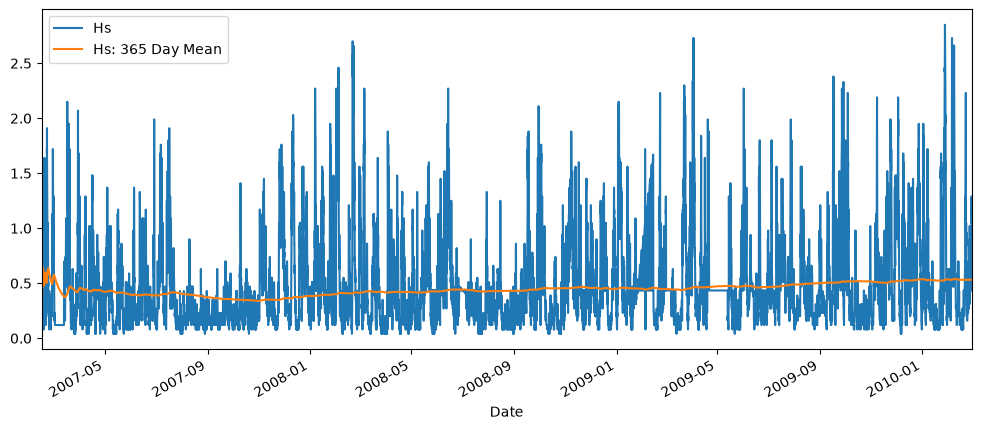

In [57]:
df['Hs: 365 Day Mean'] = df['Hs'].rolling(window='365D').mean() # Add a new column
ax = df[['Hs','Hs: 365 Day Mean']].plot(figsize=(12,5))
ax.autoscale(axis='x',tight=True)

## Expanding

Instead of calculating values for a rolling window of dates, what if you wanted to take into account everything from the start of the time series up to each point in time? For example, instead of considering the average over the last 7 days, we would consider all prior data in our expanding set of averages.

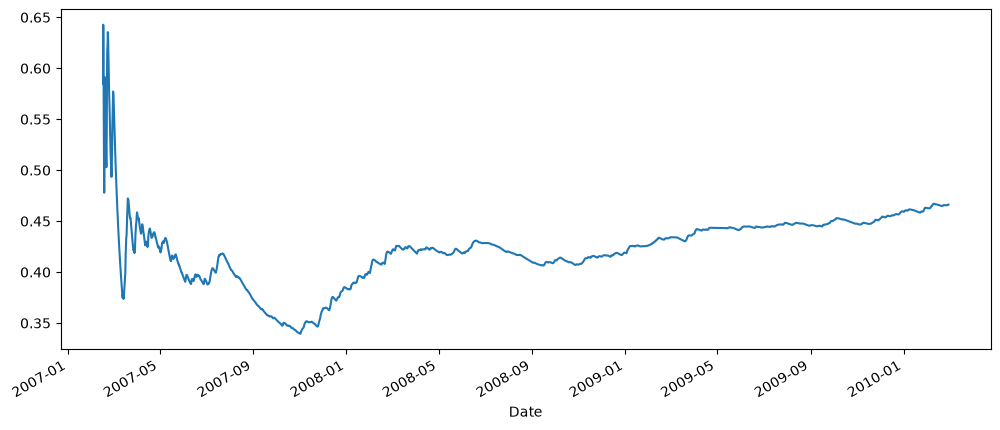

In [58]:
# Optional: specify a minimum number of periods to start from
df['Hs'].expanding(min_periods=30).mean().plot(figsize=(12,5));